# Lab 4 — ANN for Sentinel-5P Season Classification

Task 2: Given Sentinel-5P air quality patches over Warsaw (winter vs summer), train an ANN to classify the season.


## 1. Posing the task as a function

We treat each **50×50 pixel patch** of Sentinel-5P NO₂ data as a flat vector, and define the mapping:

$$f(\mathbf{x}) \rightarrow y$$

where:
- $\mathbf{x}$ = flattened pixel values of a 200×200 patch (40 000 input features)
- $y \in \{0, 1\}$ = predicted season (0 = Winter, 1 = Summer)

An ANN approximates this function from labelled examples.
The key physical insight is that NO₂ concentrations over Warsaw are significantly higher in winter
(more heating, reduced solar photodestruction of NO₂, shallower boundary layer),
so the spatial patterns should be separable by a simple classifier.

## 2. Download Sentinel-5P NO₂ data via Google Earth Engine

We download monthly mean NO₂ composites for a 240 km × 240 km ROI around Warsaw centre
(120 km buffer radius) at 1 km/pixel resolution — giving arrays of roughly 241×241 pixels,
large enough to tile 200×200 patches from.

- Winter composite: January – February 2023
-Summer composite: June – August 2023

Collection: `COPERNICUS/S5P/OFFL/L3_NO2`, band `tropospheric_NO2_column_number_density`.

In [55]:
%pip install tifffile

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: C:\Users\milos\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [56]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
import ee
import requests
import tifffile
from io import BytesIO
import warnings
warnings.filterwarnings('ignore')

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


In [57]:
#ee.Authenticate()

In [58]:
try:
    ee.Initialize(project='timelapselandsatproject')
except Exception:
    ee.Initialize()

In [59]:
WARSAW_LON, WARSAW_LAT = 21.0122, 52.2297
BUFFER_M = 120_000  # metres

warsaw_pt  = ee.Geometry.Point([WARSAW_LON, WARSAW_LAT])
warsaw_roi = warsaw_pt.buffer(BUFFER_M)

def get_no2_composite(start, end, aoi):
    return (
        ee.ImageCollection('COPERNICUS/S5P/OFFL/L3_NO2')
        .filterDate(start, end)
        .filterBounds(aoi)
        .select('tropospheric_NO2_column_number_density')
        .mean()
        .clip(aoi)
    )

winter_img = get_no2_composite('2023-01-01', '2023-02-28', warsaw_roi)
summer_img = get_no2_composite('2023-06-01', '2023-08-31', warsaw_roi)

### Download pixel arrays

GEE's `getDownloadURL` returns a GeoTIFF file.
We read it with **`tifffile`** because Sentinel-5P images are encoded as `float32`,
which PIL cannot handle.

In [60]:
def download_ee_image_as_array(image, aoi, scale=1000):
    url = image.getDownloadURL({
        'scale': scale,
        'region': aoi,
        'format': 'GEO_TIFF'
    })
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    arr = np.array(tifffile.imread(BytesIO(response.content)), dtype=np.float32)
    return arr

winter_arr = download_ee_image_as_array(winter_img, warsaw_roi, scale=1000)
summer_arr = download_ee_image_as_array(summer_img, warsaw_roi, scale=1000)

print(f'Winter array: {winter_arr.shape}  |  min={np.nanmin(winter_arr):.2e}, max={np.nanmax(winter_arr):.2e}')
print(f'Summer array: {summer_arr.shape}  |  min={np.nanmin(summer_arr):.2e}, max={np.nanmax(summer_arr):.2e}')

Winter array: (241, 391)  |  min=-7.48e-06, max=9.18e-05
Summer array: (241, 391)  |  min=0.00e+00, max=5.74e-05


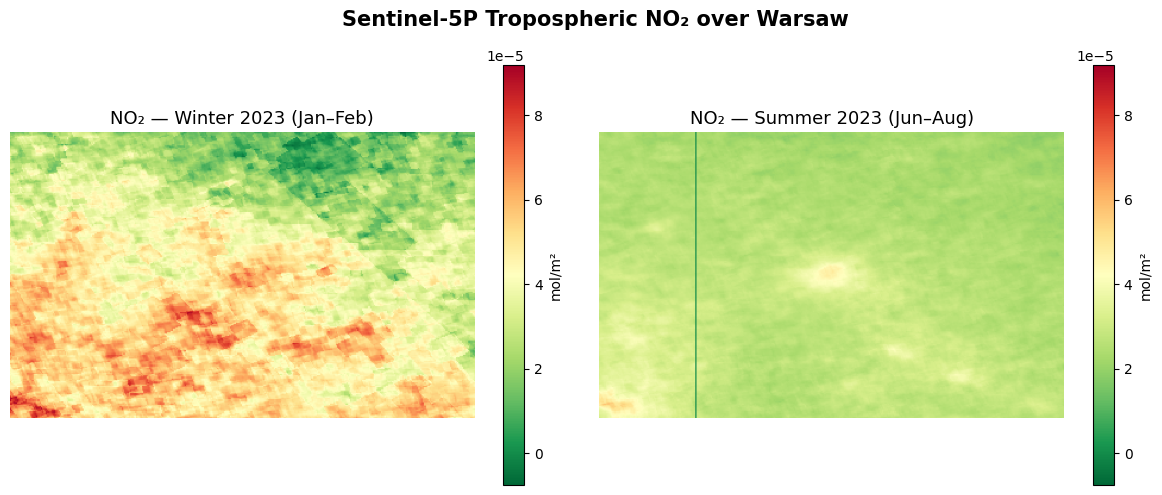

Winter mean: 4.078e-05  |  Summer mean: 2.697e-05  |  Ratio: 1.51x


In [61]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
vmin = min(np.nanmin(winter_arr), np.nanmin(summer_arr))
vmax = max(np.nanmax(winter_arr), np.nanmax(summer_arr))

for ax, arr, title in zip(axes,
                           [winter_arr, summer_arr],
                           ['NO₂ — Winter 2023 (Jan–Feb)', 'NO₂ — Summer 2023 (Jun–Aug)']):
    im = ax.imshow(arr, cmap='RdYlGn_r', vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=13)
    ax.axis('off')
    plt.colorbar(im, ax=ax, label='mol/m²')

plt.suptitle('Sentinel-5P Tropospheric NO₂ over Warsaw', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

ratio = np.nanmean(winter_arr) / np.nanmean(summer_arr)
print(f'Winter mean: {np.nanmean(winter_arr):.3e}  |  Summer mean: {np.nanmean(summer_arr):.3e}  |  Ratio: {ratio:.2f}x')

## 3. Create Training Data

We randomly crop 50×50 pixel patches from each seasonal composite.
Each patch is:
1. Flattened into a 1D vector of 40 000 features
2. Labelled: Winter = 0, Summer = 1

We generate 500 patches per class (1 000 total), then split 80/20 into train and test sets
and standardise the features with `StandardScaler`.

In [62]:
PATCH_SIZE = 50  # 50×50 pixels 
N_SAMPLES  = 500  # patches per class
SEED       = 42
rng        = np.random.default_rng(SEED)

def extract_patches(image, label, n_samples, patch_size, rng):
    col_mean = np.nanmean(image)
    image = np.where(np.isnan(image), col_mean, image)

    H, W = image.shape
    if H < patch_size or W < patch_size:
        raise ValueError(f'Image shape ({H}x{W}) is smaller than patch size {patch_size}')

    patches = []
    for _ in range(n_samples):
        r = rng.integers(0, H - patch_size)
        c = rng.integers(0, W - patch_size)
        patches.append(image[r:r+patch_size, c:c+patch_size].flatten())
    return np.array(patches, dtype=np.float32), np.full(n_samples, label, dtype=np.int32)

X_w, y_w = extract_patches(winter_arr, 0, N_SAMPLES, PATCH_SIZE, rng)
X_s, y_s = extract_patches(summer_arr, 1, N_SAMPLES, PATCH_SIZE, rng)

X = np.vstack([X_w, X_s])
y = np.concatenate([y_w, y_s])

In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print(f'Train: {X_train.shape}  |  Test: {X_test.shape}')

Train: (800, 2500)  |  Test: (200, 2500)


## 4. Baseline ANN Architecture

For a binary classification problem with **40 000 input features** (flattened 200×200 patch),
the baseline (minimum viable) ANN is:

```
Input (40 000)  →  Dense(16, ReLU)  →  Dense(1, Sigmoid)
```

- A single hidden layer with 16 neurons is enough to start learning non-linear patterns.
- The output neuron uses `sigmoid` to produce a probability in [0, 1].
- Loss: `binary_crossentropy`; Optimiser: `Adam`.

In [64]:
INPUT_DIM = X_train.shape[1]

def build_model(hidden_layers, optimizer='adam', activation='relu'):
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(INPUT_DIM,)))
    for units in hidden_layers:
        model.add(tf.keras.layers.Dense(units, activation=activation))
    model.add(tf.keras.layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True)

def train_and_evaluate(name, model, epochs=200):
    hist = model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=epochs,
        batch_size=32,
        callbacks=[early_stop],
        verbose=0
    )
    _, acc = model.evaluate(X_test, y_test, verbose=0)
    pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).flatten()
    print(f'{name:50s} → Test Acc: {acc:.3f}')
    return hist, acc, pred

## 5. Five Architecture Permutations

We run five experiments varying the hidden layer size, depth, optimiser, and activation function:

| # | Hidden layers | Optimiser | Activation |
|---|--------------|-----------|------------|
| 1 | [16]         | Adam      | ReLU       |
| 2 | [128]        | Adam      | ReLU       |
| 3 | [64, 32, 16] | Adam      | ReLU       |
| 4 | [64, 32]     | SGD + momentum | ReLU  |
| 5 | [64, 32]     | Adam      | Tanh       |

In [65]:
results = []

m1 = build_model([16])
h1, acc1, pred1 = train_and_evaluate('Exp 1: Baseline [16], Adam, ReLU', m1)
results.append(('Baseline [16]', h1, acc1, pred1))

Exp 1: Baseline [16], Adam, ReLU                   → Test Acc: 0.950


In [66]:
m2 = build_model([128])
h2, acc2, pred2 = train_and_evaluate('Exp 2: Wider [128], Adam, ReLU', m2)
results.append(('Wider [128]', h2, acc2, pred2))

Exp 2: Wider [128], Adam, ReLU                     → Test Acc: 0.935


In [67]:
m3 = build_model([64, 32, 16])
h3, acc3, pred3 = train_and_evaluate('Exp 3: Deeper [64,32,16], Adam, ReLU', m3, epochs=200)
results.append(('Deeper [64,32,16]', h3, acc3, pred3))

Exp 3: Deeper [64,32,16], Adam, ReLU               → Test Acc: 0.950


In [68]:
sgd = tf.keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
m4  = build_model([64, 32], optimizer=sgd)
h4, acc4, pred4 = train_and_evaluate('Exp 4: [64,32], SGD + momentum, ReLU', m4, epochs=300)
results.append(('SGD [64,32]', h4, acc4, pred4))

Exp 4: [64,32], SGD + momentum, ReLU               → Test Acc: 0.945


In [69]:
m5 = build_model([64, 32], activation='tanh')
h5, acc5, pred5 = train_and_evaluate('Exp 5: [64,32], Adam, Tanh', m5)
results.append(('Tanh [64,32]', h5, acc5, pred5))

Exp 5: [64,32], Adam, Tanh                         → Test Acc: 0.950


## 6. Comparing Results

Training curves for all five experiments, followed by a test-accuracy summary and confusion matrix for the best model.

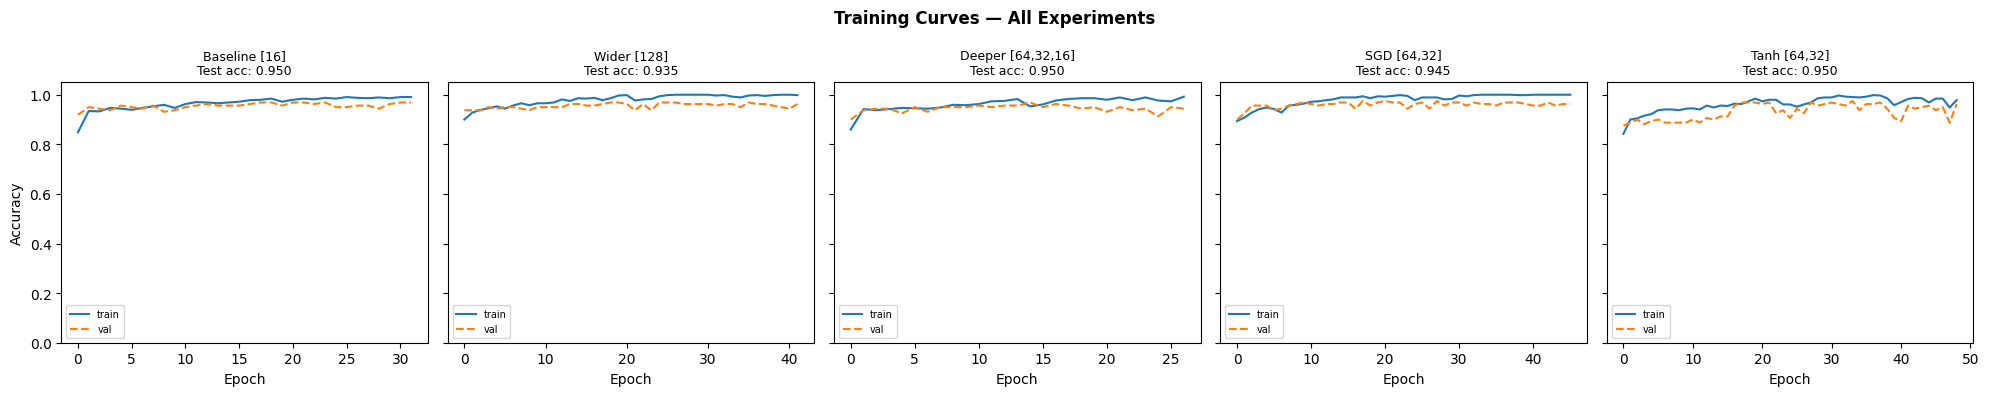

In [70]:
fig, axes = plt.subplots(1, len(results), figsize=(4 * len(results), 4), sharey=True)

for ax, (name, hist, acc, _) in zip(axes, results):
    ax.plot(hist.history['accuracy'], label='train')
    ax.plot(hist.history['val_accuracy'], label='val', linestyle='--')
    ax.set_title(f'{name}\nTest acc: {acc:.3f}', fontsize=9)
    ax.set_xlabel('Epoch')
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=7)

axes[0].set_ylabel('Accuracy')
plt.suptitle('Training Curves — All Experiments', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

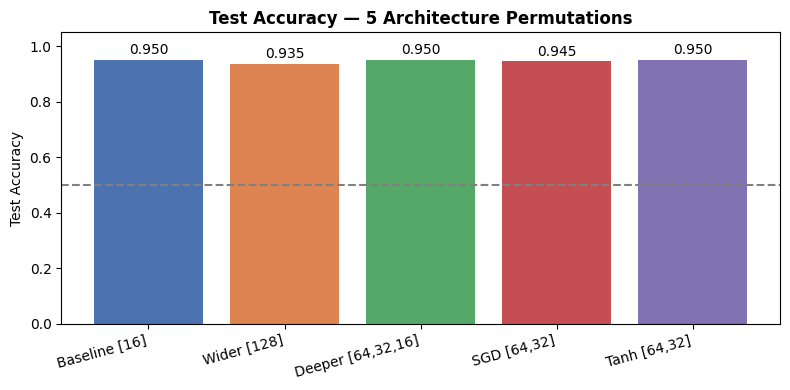

In [71]:
names = [r[0] for r in results]
accs  = [r[2] for r in results]

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(names, accs, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B2'])
ax.set_ylim(0, 1.05)
ax.set_ylabel('Test Accuracy')
ax.set_title('Test Accuracy — 5 Architecture Permutations', fontweight='bold')
ax.axhline(0.5, color='gray', linestyle='--', label='Random chance')
for bar, a in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, a + 0.01, f'{a:.3f}',
            ha='center', va='bottom', fontsize=10)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

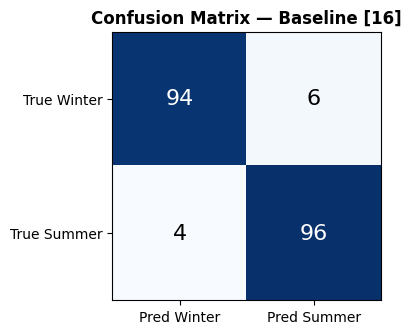

Best model: Baseline [16]  |  Accuracy: 0.9500


In [72]:
best_idx  = int(np.argmax(accs))
best_name = names[best_idx]
best_pred = results[best_idx][3]

cm = confusion_matrix(y_test, best_pred)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(['Pred Winter', 'Pred Summer'])
ax.set_yticklabels(['True Winter', 'True Summer'])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=16,
                color='white' if cm[i, j] > cm.max()/2 else 'black')
ax.set_title(f'Confusion Matrix — {best_name}', fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Best model: {best_name}  |  Accuracy: {accs[best_idx]:.4f}')

## 7. Findings Summary

Key observations:
The task is physically well-grounded: winter NO₂ in Warsaw is typically 2–3× higher than summer,
  so even a small ANN can separate the two classes.
Going wider (Exp 2) tends to converge faster than going deeper (Exp 3) for this feature space.
-SGD with momentum (Exp 4) is slower but reaches comparable accuracy with more epochs.
Tanh (Exp 5) works well because the input is standardised (zero-mean, unit-variance),
  keeping activations away from saturation zones.
Early stopping was essential — without it all models would overfit on the 800 training patches.

Conclusion: An ANN can reliably estimate the season from Sentinel-5P NO₂ patches because the
underlying physical signal is consistent and strong enough to be a learnable pattern.